# Week 11 — Random Forest and Bagging

## Objective

Evaluate whether tree ensembles improve road accident risk ranking compared with single decision trees and logistic regression.

## Experimental setup

- Dataset: Toronto signalized intersection-day observations.
- Prediction horizon: one day.
- Task: rare-event binary classification and relative-risk ranking.
- Features: unchanged Week 9 feature set.
- Validation: unchanged chronological split and temporal cross-validation.
- Primary metric: Average Precision.

## Research questions

1. Does Random Forest outperform a single Decision Tree?
2. Does Random Forest outperform Logistic Regression?
3. Does class weighting improve ranking performance?
4. Are the improvements consistent across temporal folds?
5. Which features contribute most to the fitted ensemble?

All results remain exploratory development results. No untouched final test period is evaluated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import average_precision_score

In [2]:
df = pd.read_csv(
    "../data/processed/intersection_day_2018_features.csv",
    parse_dates=["prediction_date", "target_date"]
)

print("Dataset shape:", df.shape)
print("Positive observations:", df["target"].sum())

print("\nDataset columns:")
print(df.columns.tolist())

df.head()

Dataset shape: (823217, 16)
Positive observations: 119

Dataset columns:
['intersection_id', 'prediction_date', 'target_date', 'historical_ksi_count', 'historical_traffic_volume', 'day_of_week', 'month', 'target', 'ksi_count_30d', 'ksi_count_365d', 'is_weekend', 'traffic_missing', 'weather_date', 'temperature_prev_day', 'precipitation_prev_day', 'weather_missing']


,intersection_id,prediction_date,target_date,historical_ksi_count,historical_traffic_volume,day_of_week,month,target,ksi_count_30d,ksi_count_365d,is_weekend,traffic_missing,weather_date,temperature_prev_day,precipitation_prev_day,weather_missing
0,3,2018-01-01,2018-01-02,0,12960.0,1,1,0,0,0,0,0,2017-12-31,-18.6,0.0,0
1,3,2018-01-02,2018-01-03,0,12960.0,2,1,0,0,0,0,0,2018-01-01,-15.0,0.0,0
2,3,2018-01-03,2018-01-04,0,12960.0,3,1,0,0,0,0,0,2018-01-02,-10.5,1.0,0
3,3,2018-01-04,2018-01-05,0,12960.0,4,1,0,0,0,0,0,2018-01-03,-9.9,0.0,0
4,3,2018-01-05,2018-01-06,0,12960.0,5,1,0,0,0,1,0,2018-01-04,-14.7,0.0,0


In [3]:
numerical_features = [
    "historical_ksi_count",
    "historical_traffic_volume",
    "ksi_count_30d",
    "ksi_count_365d",
    "temperature_prev_day",
    "precipitation_prev_day"
]

categorical_features = [
    "day_of_week",
    "month"
]

binary_features = [
    "is_weekend",
    "traffic_missing",
    "weather_missing"
]

feature_columns = (
    numerical_features
    + categorical_features
    + binary_features
)

X = df[feature_columns].copy()
y = df["target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", len(feature_columns))

X shape: (823217, 11)
y shape: (823217,)
Number of features: 11


In [4]:
train_mask = df["prediction_date"] <= "2018-09-29"
val_mask = df["prediction_date"] >= "2018-10-01"

X_train = X.loc[train_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)

X_val = X.loc[val_mask].reset_index(drop=True)
y_val = y.loc[val_mask].reset_index(drop=True)

train_dates = df.loc[
    train_mask, "prediction_date"
].reset_index(drop=True)

val_dates = df.loc[
    val_mask, "prediction_date"
].reset_index(drop=True)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("Train positives:", y_train.sum())
print("Validation positives:", y_val.sum())

Train shape: (613223, 11)
Validation shape: (207736, 11)
Train positives: 81
Validation positives: 38


In [5]:
unique_dates = pd.Index(
    train_dates.unique()
).sort_values()

tscv = TimeSeriesSplit(
    n_splits=3,
    gap=1
)

cv_splits = []

for train_date_idx, val_date_idx in tscv.split(unique_dates):

    fold_train_dates = unique_dates[train_date_idx]
    fold_val_dates = unique_dates[val_date_idx]

    train_idx = np.flatnonzero(
        train_dates.isin(fold_train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_dates.isin(fold_val_dates).to_numpy()
    )

    cv_splits.append((train_idx, val_idx))

print("Unique training dates:", len(unique_dates))
print("Number of CV folds:", len(cv_splits))

Unique training dates: 272
Number of CV folds: 3


In [6]:
fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    cv_splits, start=1
):
    fold_train = train_dates.iloc[train_idx]
    fold_val = train_dates.iloc[val_idx]

    fold_train_y = y_train.iloc[train_idx]
    fold_val_y = y_train.iloc[val_idx]

    assert fold_train.max() + pd.Timedelta(days=1) < fold_val.min()
    assert fold_train_y.nunique() == 2
    assert fold_val_y.nunique() == 2

    fold_summary.append({
        "fold": fold,
        "train_start": fold_train.min().date(),
        "train_end": fold_train.max().date(),
        "val_start": fold_val.min().date(),
        "val_end": fold_val.max().date(),
        "train_rows": len(train_idx),
        "val_rows": len(val_idx),
        "train_positives": fold_train_y.sum(),
        "val_positives": fold_val_y.sum()
    })

pd.DataFrame(fold_summary)

,fold,train_start,train_end,val_start,val_end,train_rows,val_rows,train_positives,val_positives
0,1,2018-01-01,2018-03-08,2018-03-10,2018-05-16,150929,153204,14,20
1,2,2018-01-01,2018-05-15,2018-05-17,2018-07-23,304133,153315,34,18
2,3,2018-01-01,2018-07-22,2018-07-24,2018-09-29,457444,153522,51,29


In [7]:
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features),
    ("bin", "passthrough", binary_features)
], remainder="drop")

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [8]:
from sklearn.base import clone

rf_params = {
    "n_estimators": 100,
    "criterion": "gini",
    "max_depth": 5,
    "min_samples_leaf": 10,
    "max_features": "sqrt",
    "bootstrap": True,
    "random_state": 42,
    "n_jobs": -1
}

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        **rf_params,
        class_weight=None
    ))
])

rf_balanced_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        **rf_params,
        class_weight="balanced"
    ))
])

models = {
    "Random Forest": rf_pipeline,
    "Random Forest Balanced": rf_balanced_pipeline
}

In [9]:
cv_results = []

for model_name, pipeline in models.items():

    print(f"Evaluating: {model_name}", flush=True)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "model": model_name,
        "fold_1_ap": scores["test_score"][0],
        "fold_2_ap": scores["test_score"][1],
        "fold_3_ap": scores["test_score"][2],
        "mean_train_ap": scores["train_score"].mean(),
        "mean_cv_ap": scores["test_score"].mean(),
        "std_cv_ap": scores["test_score"].std(),
        "mean_fit_time": scores["fit_time"].mean()
    })

    print(
        f"Mean CV AP: {scores['test_score'].mean():.6f}",
        flush=True
    )

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    "mean_cv_ap",
    ascending=False
).round(6)

Evaluating: Random Forest
Mean CV AP: 0.000272
Evaluating: Random Forest Balanced
Mean CV AP: 0.000285


,model,fold_1_ap,fold_2_ap,fold_3_ap,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time
1,Random Forest Balanced,0.000168,0.000373,0.000312,0.117955,0.000285,0.000086,13.007913
0,Random Forest,0.000155,0.000319,0.000343,0.114857,0.000272,0.000084,7.813249


In [10]:
best_model_name = cv_results_df.loc[
    cv_results_df["mean_cv_ap"].idxmax(),
    "model"
]

best_pipeline = clone(models[best_model_name])

best_pipeline.fit(X_train, y_train)

train_scores = best_pipeline.predict_proba(X_train)[:, 1]
val_scores = best_pipeline.predict_proba(X_val)[:, 1]

train_ap = average_precision_score(y_train, train_scores)
val_ap = average_precision_score(y_val, val_scores)

best_cv_ap = cv_results_df["mean_cv_ap"].max()

print("Selected model:", best_model_name)
print(f"Train AP:      {train_ap:.6f}")
print(f"Mean CV AP:    {best_cv_ap:.6f}")
print(f"Validation AP: {val_ap:.6f}")

Selected model: Random Forest Balanced
Train AP:      0.019464
Mean CV AP:    0.000285
Validation AP: 0.000409


In [11]:
baseline_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            C=0.1,
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            criterion="gini",
            max_depth=3,
            random_state=42
        ))
    ])
}

In [12]:
baseline_results = []

for model_name, pipeline in baseline_models.items():

    print(f"Evaluating: {model_name}", flush=True)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    fitted_pipeline = clone(pipeline)
    fitted_pipeline.fit(X_train, y_train)

    validation_scores = fitted_pipeline.predict_proba(X_val)[:, 1]

    baseline_results.append({
        "model": model_name,
        "fold_1_ap": scores["test_score"][0],
        "fold_2_ap": scores["test_score"][1],
        "fold_3_ap": scores["test_score"][2],
        "mean_train_ap": scores["train_score"].mean(),
        "mean_cv_ap": scores["test_score"].mean(),
        "std_cv_ap": scores["test_score"].std(),
        "mean_fit_time": scores["fit_time"].mean(),
        "validation_ap": average_precision_score(
            y_val,
            validation_scores
        )
    })

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df.round(6)

Evaluating: Logistic Regression
Evaluating: Decision Tree


,model,fold_1_ap,fold_2_ap,fold_3_ap,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time,validation_ap
0,Logistic Regression,0.000243,0.000522,0.002162,0.000235,0.000976,0.000846,0.542045,0.000389
1,Decision Tree,0.000123,0.000233,0.000302,0.002095,0.000219,0.000074,0.622816,0.000242


In [13]:
rf_results_df = cv_results_df.copy()

rf_results_df["validation_ap"] = np.nan

rf_results_df.loc[
    rf_results_df["model"] == best_model_name,
    "validation_ap"
] = val_ap

comparison_df = pd.concat(
    [baseline_results_df, rf_results_df],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    "mean_cv_ap",
    ascending=False
).reset_index(drop=True)

comparison_df[[
    "model",
    "fold_1_ap",
    "fold_2_ap",
    "fold_3_ap",
    "mean_train_ap",
    "mean_cv_ap",
    "std_cv_ap",
    "validation_ap"
]].round(6)

,model,fold_1_ap,fold_2_ap,fold_3_ap,mean_train_ap,mean_cv_ap,std_cv_ap,validation_ap
0,Logistic Regression,0.000243,0.000522,0.002162,0.000235,0.000976,0.000846,0.000389
1,Random Forest Balanced,0.000168,0.000373,0.000312,0.117955,0.000285,0.000086,0.000409
2,Random Forest,0.000155,0.000319,0.000343,0.114857,0.000272,0.000084,NaN
3,Decision Tree,0.000123,0.000233,0.000302,0.002095,0.000219,0.000074,0.000242


In [14]:
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_model = best_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
feature_importances = fitted_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importances
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

importance_df.round(6)

,feature,importance
0,num__historical_traffic_volume,0.234643
1,num__temperature_prev_day,0.187178
2,num__historical_ksi_count,0.127754
3,bin__traffic_missing,0.114420
4,num__precipitation_prev_day,0.050637
5,cat__month_3,0.035635
6,cat__day_of_week_6,0.034137
7,cat__day_of_week_1,0.033194
8,cat__month_1,0.025103
9,cat__month_2,0.019773


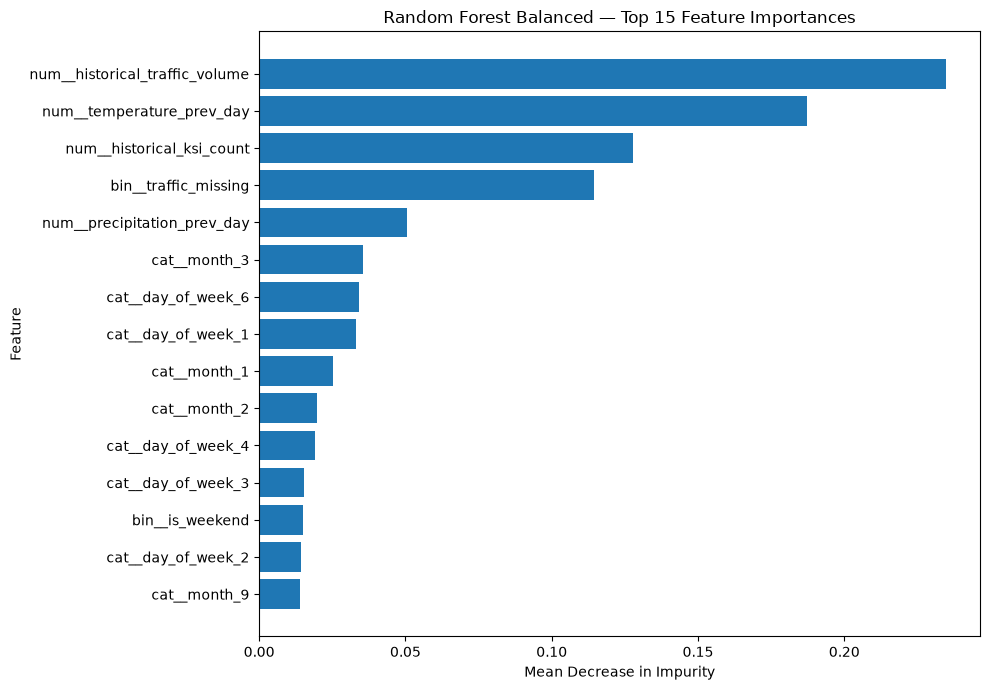

In [15]:
top_features = importance_df.head(15).sort_values(
    "importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Feature")
plt.title("Random Forest Balanced — Top 15 Feature Importances")

plt.tight_layout()
plt.show()

## Week 11 — Conclusions

### Experimental results

Two Random Forest configurations were evaluated using
the unchanged Week 9 feature set and three temporal CV folds.

| Model | Mean CV AP | Validation AP |
|---|---:|---:|
| Logistic Regression | 0.000976 | 0.000389 |
| Random Forest Balanced | 0.000285 | 0.000409 |
| Random Forest | 0.000272 | Not evaluated |
| Decision Tree | 0.000219 | 0.000242 |

### Main findings

- Both Random Forest configurations outperformed the
  single Decision Tree on all three temporal folds.

- Logistic Regression achieved the highest Average
  Precision on every temporal fold.

- Class weighting increased mean Random Forest CV AP
  by approximately 4.8%, but the improvement was not
  consistent across all folds.

- Random Forest Balanced achieved the highest AP on
  the development validation period among evaluated
  models, but its advantage over Logistic Regression
  was small.

- A substantial gap between training and temporal
  validation performance indicates that overfitting
  remains a concern.

### Feature importance

The four most important transformed features in the
selected Random Forest were:

| Feature | MDI importance |
|---|---:|
| Historical traffic volume | 0.234643 |
| Previous-day temperature | 0.187178 |
| Historical KSI count | 0.127754 |
| Traffic missing indicator | 0.114420 |

Together, these features accounted for approximately
66.4% of the total impurity-based importance.

These importances describe the fitted ensemble and
must not be interpreted as causal effects or evidence
of stable predictive usefulness.

### Model selection

Logistic Regression remains the preferred development
model based on mean temporal CV Average Precision.

Random Forest Balanced is retained as an alternative
candidate for future comparisons.

### Limitations

- Extreme class imbalance.
- Limited number of positive training observations.
- Incomplete collision-to-intersection matching.
- Limited traffic and weather coverage.
- Potential temporal distribution shift.
- Uncalibrated risk scores.
- No untouched final test evaluation.

### Next steps

- Evaluate gradient boosting models.
- Extend the temporal coverage of the dataset.
- Investigate probability calibration and error slices.
- Reserve an untouched chronological final test period.